# 01 · Análisis Exploratorio de Datos (EDA) — HMS Harmful Brain Activity

**Fase CRISP-DM:** 2 – Comprensión de los datos

Dataset: competencia de Kaggle *HMS – Harmful Brain Activity Classification*. Cada fila de
`train.csv` es una ventana de EEG de **50 s** (y su espectrograma de **10 min**) que un grupo de
expertos clasificó en 6 categorías: *Seizure, LPD, GPD, LRDA, GRDA, Other*. El objetivo no es una
etiqueta dura sino la **distribución de votos** de los expertos, y la métrica oficial es la
**divergencia KL** entre la distribución real y la predicha.

Contenido:
1. Inventario de archivos
2. Estructura de `train.csv` (tipos, nulos, cardinalidades)
3. Variable objetivo: consenso, votos y acuerdo entre expertos
4. Jerarquía EEG → sub-ventanas → pacientes (y riesgo de fuga)
5. Señal EEG cruda: canales, calidad, amplitudes, ejemplos por clase
6. Espectrogramas de Kaggle: estructura, faltantes, ejemplos por clase
7. Potencia por bandas de frecuencia por clase
8. Conclusiones e implicaciones para el modelado

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../.."))  # raíz del repo (notebooks/iteracion_2/ -> ../..)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from src.config import DATA_DIR, CACHE_DIR, FIGURES_DIR, TARGETS, CLASSES, EEG_FS, CHAINS
from src.data_preparation import load_train, consolidate_by_eeg, add_folds
from src.features import read_eeg, read_kaggle_spectrogram, eeg_window, clean_eeg, bipolar_montage, kaggle_spec_window
from src.viz import set_style, CLASS_COLORS, SEQ_CMAP

set_style()
pd.set_option("display.max_columns", 30)
FIG = FIGURES_DIR / "eda"; FIG.mkdir(exist_ok=True, parents=True)
print("Datos en:", DATA_DIR)

Datos en: C:\Users\Luis\hms_data\raw


## 1. Inventario de archivos

In [2]:
inv = []
for name in ["train.csv", "test.csv", "sample_submission.csv"]:
    inv.append({"recurso": name, "archivos": 1, "tamaño_MB": (DATA_DIR / name).stat().st_size / 1e6})
for d in ["train_eegs", "train_spectrograms", "test_eegs", "test_spectrograms"]:
    files = list((DATA_DIR / d).glob("*.parquet"))
    inv.append({"recurso": d, "archivos": len(files), "tamaño_MB": sum(f.stat().st_size for f in files) / 1e6})
pd.DataFrame(inv).round(1)

,recurso,archivos,tamaño_MB
0,train.csv,1,7.6
1,test.csv,1,0.0
2,sample_submission.csv,1,0.0
3,train_eegs,17300,19064.4
4,train_spectrograms,11138,7312.8
5,test_eegs,1,0.9
6,test_spectrograms,1,0.5


El conjunto de prueba público solo trae 1 ejemplo (la evaluación real era oculta), por lo que
**toda la validación se hace con validación cruzada sobre `train`**.

## 2. Estructura de `train.csv`

In [3]:
train = load_train()
print(train.shape)
display(train.head())
display(train.dtypes.to_frame("dtype").T)

(106800, 15)


,eeg_id,eeg_sub_id,eeg_label_offset_seconds,spectrogram_id,spectrogram_sub_id,spectrogram_label_offset_seconds,label_id,patient_id,expert_consensus,seizure_vote,lpd_vote,gpd_vote,lrda_vote,grda_vote,other_vote
0,1628180742,0,0.0,353733,0,0.0,127492639,42516,Seizure,3,0,0,0,0,0
1,1628180742,1,6.0,353733,1,6.0,3887563113,42516,Seizure,3,0,0,0,0,0
2,1628180742,2,8.0,353733,2,8.0,1142670488,42516,Seizure,3,0,0,0,0,0
3,1628180742,3,18.0,353733,3,18.0,2718991173,42516,Seizure,3,0,0,0,0,0
4,1628180742,4,24.0,353733,4,24.0,3080632009,42516,Seizure,3,0,0,0,0,0


,eeg_id,eeg_sub_id,eeg_label_offset_seconds,spectrogram_id,spectrogram_sub_id,spectrogram_label_offset_seconds,label_id,patient_id,expert_consensus,seizure_vote,lpd_vote,gpd_vote,lrda_vote,grda_vote,other_vote
dtype,int64,int64,float64,int64,int64,float64,int64,int64,str,int64,int64,int64,int64,int64,int64


In [4]:
summary = pd.DataFrame({
    "nulos": train.isna().sum(),
    "valores_únicos": train.nunique(),
    "min": train.min(numeric_only=True),
    "max": train.max(numeric_only=True),
})
summary

,nulos,valores_únicos,min,max
eeg_id,0,17089,568657.0,4.294958e+09
eeg_label_offset_seconds,0,1502,0.0,3.372000e+03
eeg_sub_id,0,743,0.0,7.420000e+02
expert_consensus,0,6,NaN,NaN
gpd_vote,0,17,0.0,1.600000e+01
grda_vote,0,16,0.0,1.500000e+01
label_id,0,106800,338.0,4.294934e+09
lpd_vote,0,19,0.0,1.800000e+01
lrda_vote,0,16,0.0,1.500000e+01
other_vote,0,26,0.0,2.500000e+01


In [5]:
print("Filas duplicadas:", train.duplicated().sum())
print("label_id duplicados:", train.label_id.duplicated().sum())
train[["eeg_label_offset_seconds", "spectrogram_label_offset_seconds"] + TARGETS].describe().T.round(2)

Filas duplicadas: 0
label_id duplicados: 0


,count,mean,std,min,25%,50%,75%,max
eeg_label_offset_seconds,106800.0,118.82,314.56,0.0,6.0,26.0,82.0,3372.0
spectrogram_label_offset_seconds,106800.0,520.43,1449.76,0.0,12.0,62.0,394.0,17632.0
seizure_vote,106800.0,0.88,1.54,0.0,0.0,0.0,1.0,19.0
lpd_vote,106800.0,1.14,2.82,0.0,0.0,0.0,1.0,18.0
gpd_vote,106800.0,1.26,3.13,0.0,0.0,0.0,0.0,16.0
lrda_vote,106800.0,0.95,2.14,0.0,0.0,0.0,1.0,15.0
grda_vote,106800.0,1.06,2.23,0.0,0.0,0.0,1.0,15.0
other_vote,106800.0,1.97,3.62,0.0,0.0,0.0,2.0,25.0


No hay valores faltantes en el CSV ni duplicados exactos. Las columnas `*_vote` son **conteos** de
expertos, no probabilidades: hay que normalizarlas por fila.

## 3. Variable objetivo
### 3.1 Consenso de expertos (clase mayoritaria)

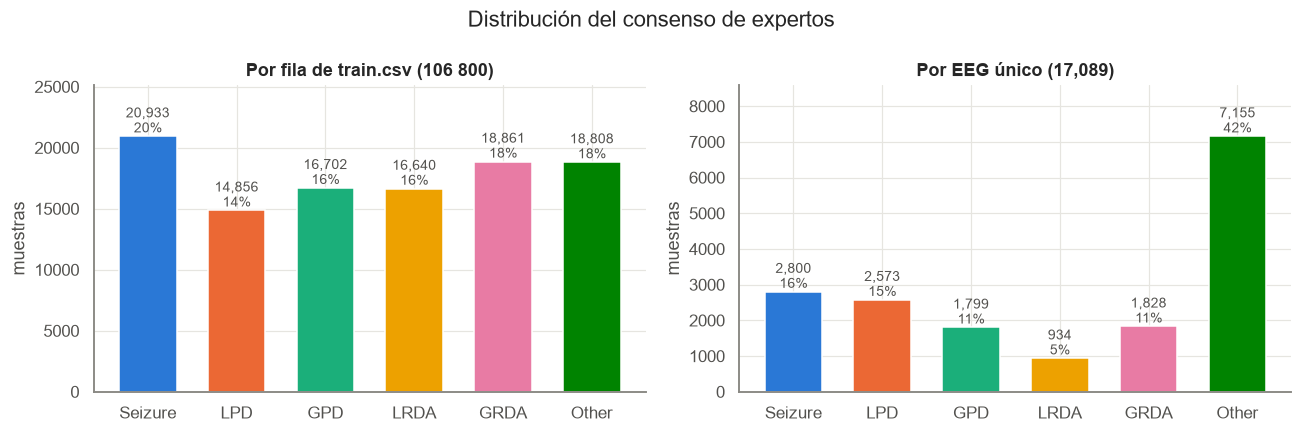

,filas,% filas,eeg_unicos,% eeg
expert_consensus,,,,
Seizure,20933,19.6,2800,16.4
LPD,14856,13.9,2573,15.1
GPD,16702,15.6,1799,10.5
LRDA,16640,15.6,934,5.5
GRDA,18861,17.7,1828,10.7
Other,18808,17.6,7155,41.9


In [6]:
cons = train.expert_consensus.value_counts().reindex(CLASSES)
eeg_level = consolidate_by_eeg(train)
cons_eeg = eeg_level.expert_consensus.value_counts().reindex(CLASSES)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s, title in [(axes[0], cons, "Por fila de train.csv (106 800)"),
                     (axes[1], cons_eeg, f"Por EEG único ({len(eeg_level):,})")]:
    ax.bar(s.index, s.values, color=[CLASS_COLORS[c] for c in s.index], width=0.65)
    for i, v in enumerate(s.values):
        ax.text(i, v, f"{v:,}\n{v / s.sum():.0%}", ha="center", va="bottom", fontsize=9, color="#52514e")
    ax.set_title(title); ax.set_ylabel("muestras"); ax.margins(y=0.2)
fig.suptitle("Distribución del consenso de expertos")
fig.tight_layout(); fig.savefig(FIG / "consenso_clases.png"); plt.show()
pd.DataFrame({"filas": cons, "% filas": (cons / cons.sum() * 100).round(1),
              "eeg_unicos": cons_eeg, "% eeg": (cons_eeg / cons_eeg.sum() * 100).round(1)})

### 3.2 Número de votos por muestra
El número de expertos que anotó cada ventana varía mucho. La literatura de la competencia
(y el propio foro) mostró que las ventanas con pocos votos tienen etiquetas sistemáticamente
distintas a las de muchos votos.

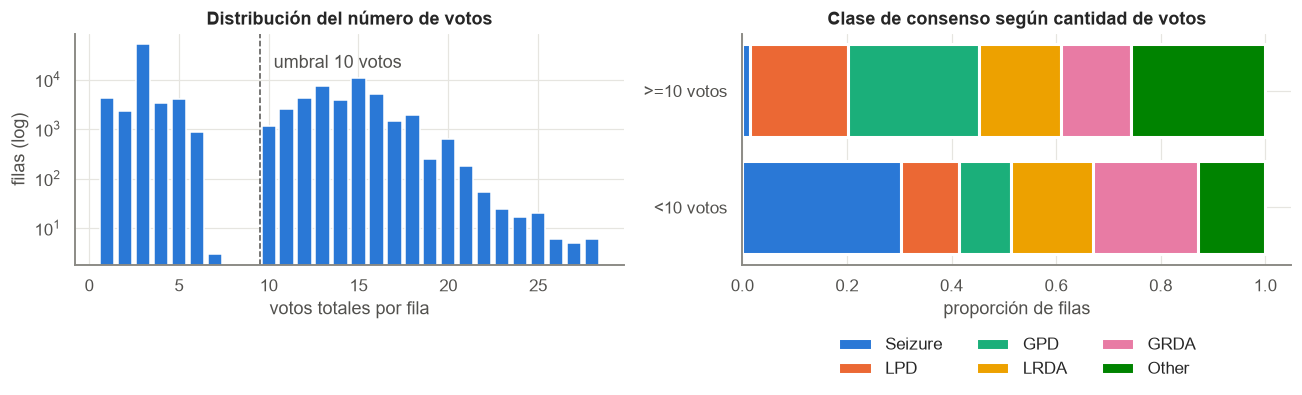

calidad
<10 votos     66854
>=10 votos    39946
Name: count, dtype: int64


expert_consensus,Seizure,LPD,GPD,LRDA,GRDA,Other
calidad,,,,,,
<10 votos,30.4,11.1,9.9,15.6,20.2,12.8
>=10 votos,1.5,18.6,25.2,15.6,13.5,25.6


In [7]:
train["total_votes"] = train[TARGETS].sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
vc = train.total_votes.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color="#2a78d6", width=0.8)
axes[0].set_yscale("log"); axes[0].set_xlabel("votos totales por fila"); axes[0].set_ylabel("filas (log)")
axes[0].set_title("Distribución del número de votos")
axes[0].axvline(9.5, color="#52514e", ls="--", lw=1); axes[0].text(10, vc.max() / 3, " umbral 10 votos", color="#52514e")

train["calidad"] = np.where(train.total_votes >= 10, ">=10 votos", "<10 votos")
ct = pd.crosstab(train.calidad, train.expert_consensus, normalize="index").reindex(columns=CLASSES)
left = np.zeros(len(ct))
for c in CLASSES:
    axes[1].barh(ct.index, ct[c], left=left, color=CLASS_COLORS[c], label=c, edgecolor="white", linewidth=2)
    left += ct[c].values
axes[1].set_xlabel("proporción de filas"); axes[1].set_title("Clase de consenso según cantidad de votos")
axes[1].legend(ncol=3, bbox_to_anchor=(0.5, -0.25), loc="upper center")
fig.tight_layout(); fig.savefig(FIG / "votos_totales.png"); plt.show()
print(train.calidad.value_counts())
(ct * 100).round(1)

**Hallazgos clave:**
- ~63 % de las filas tienen menos de 10 votos (la mayoría con solo 1–3 anotadores).
- Las dos poblaciones tienen **distribuciones de clase muy diferentes**: entre las filas con <10 votos
  *Seizure* es la clase más frecuente (~30 %, seguida de GRDA ~20 %), mientras que entre las de ≥10
  votos *Seizure* casi desaparece (~1.5 %) y dominan *Other* y *GPD* (~25 % cada una).
- Por EEG único (tabla anterior) *Other* pasa a ser el 42 % de las muestras: los registros con
  muchas sub-ventanas etiquetadas son sobre todo de patrones patológicos.

Esto justifica un entrenamiento en dos etapas (todo el conjunto → afinado en muestras de alta calidad)
y reportar la métrica también sobre el subconjunto de alta calidad, que es el que más se parece
al conjunto de prueba oculto de la competencia.

### 3.3 Acuerdo entre expertos
Se mide el acuerdo como la fracción de votos de la clase mayoritaria y la entropía de la
distribución de votos (0 = unanimidad, log 6 ≈ 1.79 = máximo desacuerdo).

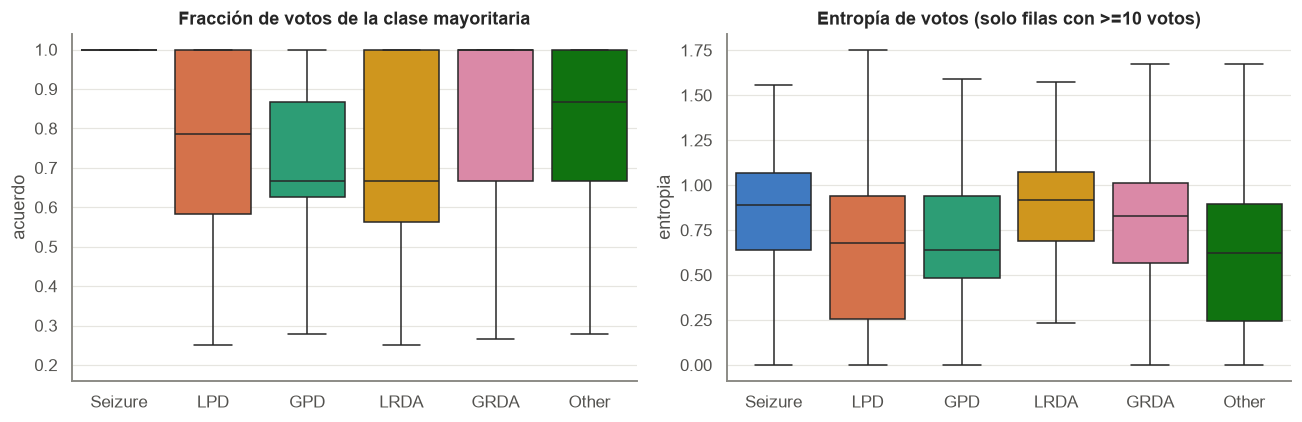

,acuerdo_medio,unanimes,entropia_media
calidad,,,
<10 votos,0.892,0.711,0.202
>=10 votos,0.688,0.088,0.703


In [8]:
P = train[TARGETS].to_numpy() / train.total_votes.to_numpy()[:, None]
train["acuerdo"] = P.max(axis=1)
with np.errstate(divide="ignore", invalid="ignore"):
    train["entropia"] = -np.nansum(np.where(P > 0, P * np.log(P), 0), 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=train, x="expert_consensus", y="acuerdo", order=CLASSES, hue="expert_consensus",
            palette=CLASS_COLORS, ax=axes[0], fliersize=0, legend=False)
axes[0].set_title("Fracción de votos de la clase mayoritaria"); axes[0].set_xlabel("")
sns.boxplot(data=train[train.total_votes >= 10], x="expert_consensus", y="entropia", order=CLASSES,
            hue="expert_consensus", palette=CLASS_COLORS, ax=axes[1], fliersize=0, legend=False)
axes[1].set_title("Entropía de votos (solo filas con >=10 votos)"); axes[1].set_xlabel("")
fig.tight_layout(); fig.savefig(FIG / "acuerdo_expertos.png"); plt.show()

agree_tbl = train.groupby("calidad").agg(acuerdo_medio=("acuerdo", "mean"),
                                         unanimes=("acuerdo", lambda s: (s == 1).mean()),
                                         entropia_media=("entropia", "mean"))
agree_tbl.round(3)

### 3.4 ¿Qué clases confunden los propios expertos?
Distribución media de votos condicionada a la clase de consenso (filas con ≥10 votos).
Fuera de la diagonal se ve la "confusión humana", que es el piso de error razonable para un modelo.

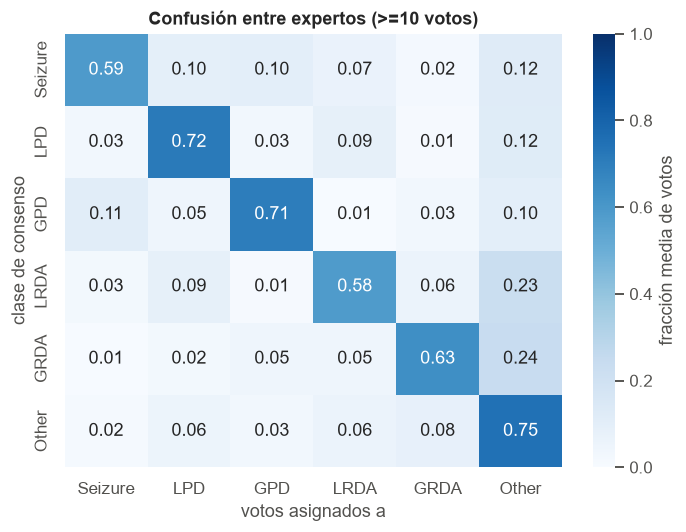

In [9]:
hq = train[train.total_votes >= 10]
Phq = hq[TARGETS].to_numpy() / hq.total_votes.to_numpy()[:, None]
conf_h = pd.DataFrame(Phq, columns=CLASSES).groupby(hq.expert_consensus.values).mean().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(conf_h, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, ax=ax, cbar_kws={"label": "fracción media de votos"})
ax.set_ylabel("clase de consenso"); ax.set_xlabel("votos asignados a")
ax.set_title("Confusión entre expertos (>=10 votos)")
fig.tight_layout(); fig.savefig(FIG / "confusion_expertos.png"); plt.show()

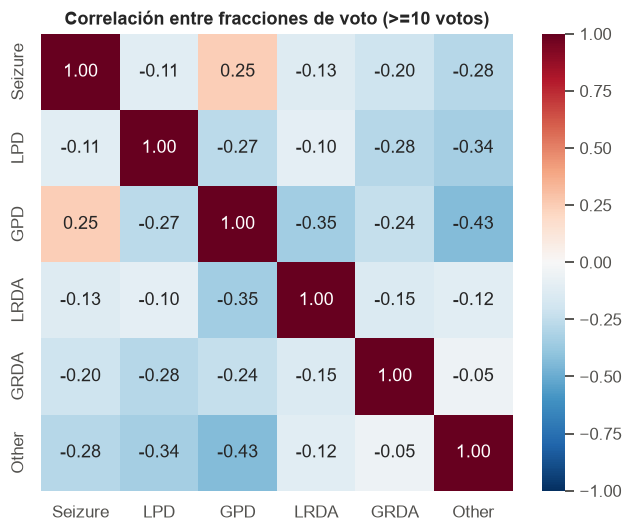

In [10]:
corr = pd.DataFrame(Phq, columns=CLASSES).corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Correlación entre fracciones de voto (>=10 votos)")
fig.tight_layout(); plt.show()

Los pares más confundidos por los expertos son los de la misma familia: **LPD↔GPD**
(periódicas lateralizadas vs. generalizadas), **LRDA↔GRDA** (rítmicas) y **Seizure↔LPD**,
además de cualquier clase con *Other*. Un buen modelo debe producir probabilidades
suaves en esos casos, no etiquetas duras: por eso se usa pérdida KL sobre la distribución
de votos completa.

## 4. Jerarquía de los datos y riesgo de fuga
Cada `eeg_id` (registro) tiene varias sub-ventanas etiquetadas (`eeg_sub_id`) que se solapan;
cada paciente puede tener varios EEG.

In [11]:
per_eeg = train.groupby("eeg_id").size()
per_pat_eeg = train.groupby("patient_id").eeg_id.nunique()
per_pat_rows = train.groupby("patient_id").size()
stats = pd.DataFrame({
    "sub-ventanas por EEG": per_eeg.describe(),
    "EEG por paciente": per_pat_eeg.describe(),
    "filas por paciente": per_pat_rows.describe(),
}).round(1)
print(f"eeg_id únicos: {train.eeg_id.nunique():,} | spectrogram_id únicos: {train.spectrogram_id.nunique():,} | pacientes: {train.patient_id.nunique():,}")
stats

eeg_id únicos: 17,089 | spectrogram_id únicos: 11,138 | pacientes: 1,950


,sub-ventanas por EEG,EEG por paciente,filas por paciente
count,17089.0,1950.0,1950.0
mean,6.2,8.8,54.8
std,17.2,20.3,133.2
min,1.0,1.0,1.0
25%,1.0,2.0,8.0
50%,3.0,3.0,19.0
75%,6.0,5.0,47.0
max,743.0,270.0,2215.0


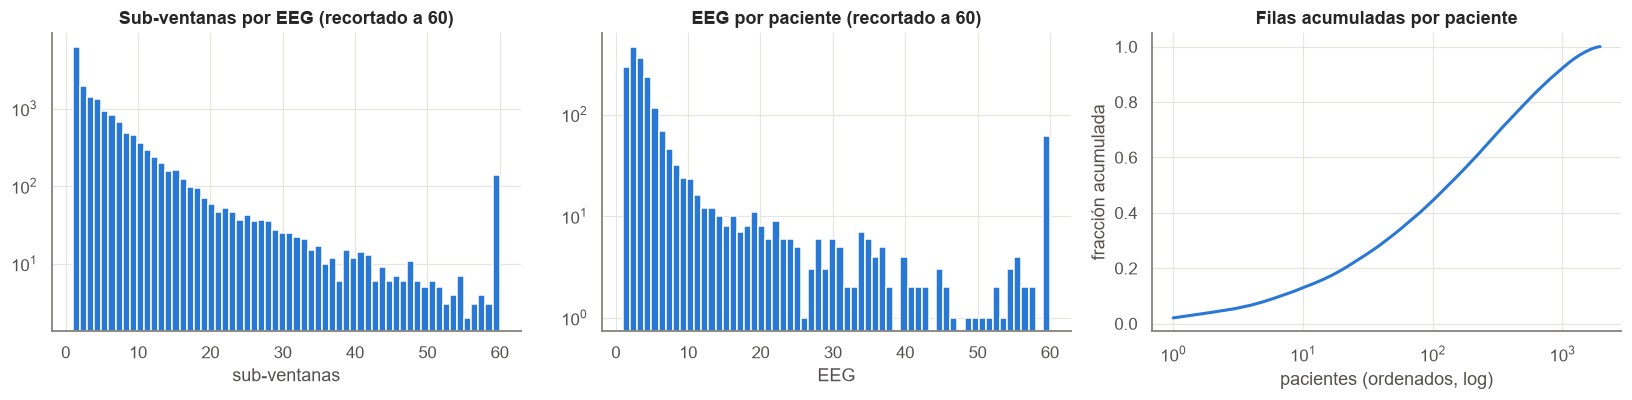

Top 1% de pacientes (19) concentra 19% de las filas


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(per_eeg.clip(upper=60), bins=60, color="#2a78d6"); axes[0].set_yscale("log")
axes[0].set_title("Sub-ventanas por EEG (recortado a 60)"); axes[0].set_xlabel("sub-ventanas")
axes[1].hist(per_pat_eeg.clip(upper=60), bins=60, color="#2a78d6"); axes[1].set_yscale("log")
axes[1].set_title("EEG por paciente (recortado a 60)"); axes[1].set_xlabel("EEG")
top = per_pat_rows.sort_values(ascending=False)
axes[2].plot(np.arange(1, len(top) + 1), top.cumsum() / top.sum(), color="#2a78d6", lw=2)
axes[2].set_xscale("log"); axes[2].set_title("Filas acumuladas por paciente"); axes[2].set_xlabel("pacientes (ordenados, log)")
axes[2].set_ylabel("fracción acumulada")
fig.tight_layout(); fig.savefig(FIG / "jerarquia.png"); plt.show()
print(f"Top 1% de pacientes ({int(len(top) * .01)}) concentra {top.iloc[:int(len(top) * .01)].sum() / top.sum():.0%} de las filas")

### 4.1 Consistencia de etiquetas dentro de un mismo EEG

In [13]:
n_patterns = train.groupby("eeg_id")[TARGETS].apply(lambda g: len(g.drop_duplicates()))
n_cons = train.groupby("eeg_id").expert_consensus.nunique()
print(f"EEG con un único patrón de votos en todas sus sub-ventanas: {(n_patterns == 1).mean():.1%}")
print(f"EEG con más de una clase de consenso: {(n_cons > 1).mean():.1%}")

EEG con un único patrón de votos en todas sus sub-ventanas: 89.4%
EEG con más de una clase de consenso: 4.6%


### 4.2 Homogeneidad de clase por paciente

In [14]:
pat_major = train.groupby("patient_id").expert_consensus.agg(lambda s: s.value_counts(normalize=True).iloc[0])
print(f"Fracción media de filas de un paciente que pertenecen a su clase más frecuente: {pat_major.mean():.2f}")
print(f"Pacientes con una sola clase: {(pat_major == 1).mean():.1%}")

Fracción media de filas de un paciente que pertenecen a su clase más frecuente: 0.85
Pacientes con una sola clase: 43.8%


**Implicaciones:**
- Las sub-ventanas de un EEG son casi duplicadas (solapan hasta 49 de 50 s y comparten etiquetas en la
  gran mayoría de los casos). Se **consolida a una muestra por `eeg_id`** (~17 k muestras) para no
  sobrerrepresentar los registros largos.
- Muchos pacientes son casi monoclase y unos pocos concentran gran parte de los datos. Si un
  paciente aparece en train y validación, el modelo puede aprender al paciente y no el patrón.
  Se usa **`StratifiedGroupKFold` agrupando por `patient_id`** (5 folds).

In [15]:
meta = add_folds(eeg_level)
fold_tbl = pd.crosstab(meta.fold, meta.expert_consensus, normalize="index").reindex(columns=CLASSES) * 100
fold_tbl["n_eeg"] = meta.fold.value_counts().sort_index()
fold_tbl["n_pacientes"] = meta.groupby("fold").patient_id.nunique()
print("Pacientes compartidos entre folds:", meta.groupby("patient_id").fold.nunique().gt(1).sum())
fold_tbl.round(1)

Pacientes compartidos entre folds: 0


expert_consensus,Seizure,LPD,GPD,LRDA,GRDA,Other,n_eeg,n_pacientes
fold,,,,,,,,
0,16.4,15.1,10.5,5.4,10.7,41.9,3418,389
1,16.4,15.1,10.5,5.5,10.7,41.9,3418,394
2,16.4,15.0,10.5,5.5,10.7,41.9,3418,393
3,16.4,15.0,10.5,5.5,10.7,41.9,3418,388
4,16.4,15.0,10.5,5.5,10.7,41.9,3417,386


Los 5 folds quedan balanceados en clases y sin pacientes compartidos.

## 5. Señal EEG cruda
### 5.1 Estructura de un archivo

In [16]:
ex = eeg_level.iloc[0]
eeg = read_eeg(ex.eeg_id)
print("Forma:", eeg.shape, f"→ {len(eeg) / EEG_FS:.0f} s a {EEG_FS} Hz")
print("Canales:", list(eeg.columns))
eeg.describe().T.round(1).head(20)

Forma: (18000, 20) → 90 s a 200 Hz
Canales: ['Fp1', 'F3', 'C3', 'P3', 'F7', 'T3', 'T5', 'O1', 'Fz', 'Cz', 'Pz', 'Fp2', 'F4', 'C4', 'P4', 'F8', 'T4', 'T6', 'O2', 'EKG']


,count,mean,std,min,25%,50%,75%,max
Fp1,18000.0,-120.0,27.2,-228.9,-138.9,-120.5,-102.2,-6.7
F3,18000.0,-123.8,27.7,-339.4,-142.5,-124.5,-106.1,55.0
C3,18000.0,-120.5,29.5,-486.6,-138.1,-121.3,-103.7,180.1
P3,18000.0,-136.9,23.1,-250.7,-152.7,-137.6,-121.8,-6.9
F7,18000.0,-143.4,31.0,-264.6,-164.7,-144.4,-124.3,12.3
T3,18000.0,-116.1,24.9,-243.4,-132.6,-116.8,-100.0,32.3
T5,18000.0,-121.4,19.8,-192.4,-134.7,-121.3,-108.3,-46.2
O1,18000.0,-117.2,35.2,-263.1,-129.5,-111.2,-95.3,-31.6
Fz,18000.0,-150.1,76.1,-455.5,-161.9,-133.6,-108.5,20.6
Cz,18000.0,-121.9,43.0,-289.5,-141.0,-119.7,-101.6,27.2


19 electrodos del sistema 10-20 + 1 canal de ECG (`EKG`). Los registros completos duran más
que los 50 s etiquetados; cada fila de `train.csv` indica el desplazamiento (`eeg_label_offset_seconds`).

### 5.2 Calidad de la señal en una muestra de registros
Se revisan ~600 EEG aleatorios: duración, valores faltantes y amplitud de la ventana etiquetada.

In [17]:
rng = np.random.default_rng(0)
sample = eeg_level.sample(600, random_state=0)
q = []
for r in sample.itertuples():
    e = read_eeg(r.eeg_id)
    w = eeg_window(e, r.eeg_offset).drop(columns="EKG")
    q.append({"eeg_id": r.eeg_id, "clase": r.expert_consensus, "dur_s": len(e) / EEG_FS,
              "nan_frac_ventana": w.isna().to_numpy().mean(),
              "canales_todo_nan": int(w.isna().all().sum()),
              "amp_p99": np.nanpercentile(np.abs(w.to_numpy()), 99),
              "std_mediana": np.nanmedian(w.std().to_numpy()),
              "canales_planos": int((w.std() < 1e-3).sum())})
q = pd.DataFrame(q)
q.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
eeg_id,600.0,2.073995e+09,1.306892e+09,1629671.000,8.867346e+08,2.108124e+09,3.230883e+09,4.284597e+09
dur_s,600.0,7.663300e+01,5.310200e+01,50.000,5.000000e+01,5.600000e+01,8.200000e+01,6.780000e+02
nan_frac_ventana,600.0,1.000000e-03,1.900000e-02,0.000,0.000000e+00,0.000000e+00,0.000000e+00,3.600000e-01
canales_todo_nan,600.0,0.000000e+00,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
amp_p99,600.0,1.384677e+03,4.252362e+03,40.930,1.026900e+02,2.099100e+02,6.140000e+02,3.484655e+04
std_mediana,600.0,3.251370e+02,1.210309e+03,7.885,2.593800e+01,4.134300e+01,9.110300e+01,1.117567e+04
canales_planos,600.0,0.000000e+00,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


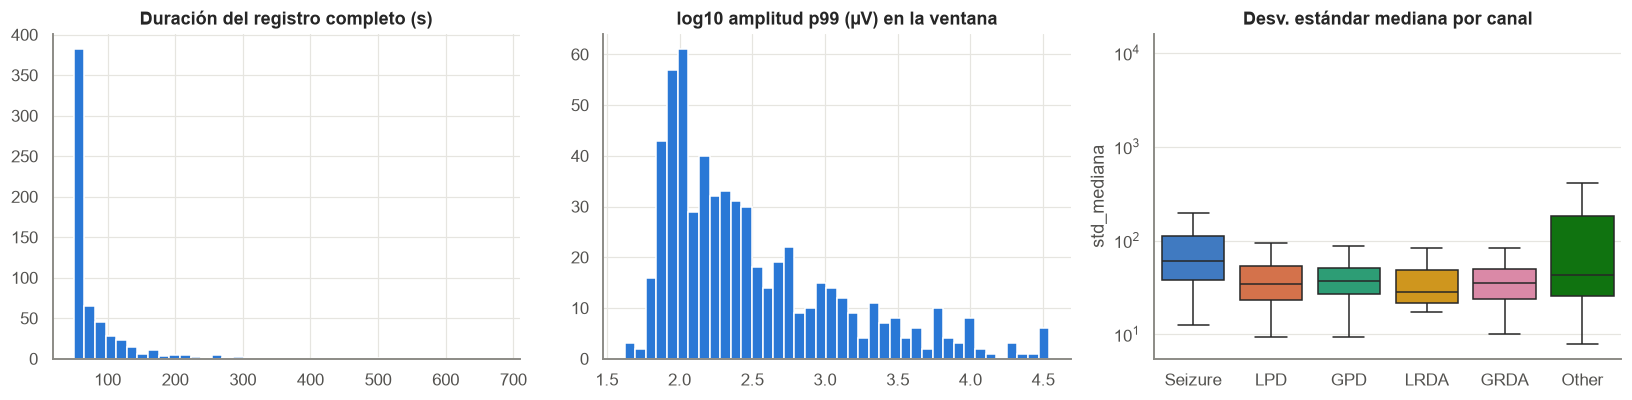

Ventanas con algún NaN: 2.5% | con amplitud p99 > 500 µV: 29.7%


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(q.dur_s, bins=40, color="#2a78d6"); axes[0].set_title("Duración del registro completo (s)")
axes[1].hist(np.log10(q.amp_p99 + 1), bins=40, color="#2a78d6"); axes[1].set_title("log10 amplitud p99 (µV) en la ventana")
sns.boxplot(data=q, x="clase", y="std_mediana", order=CLASSES, hue="clase", palette=CLASS_COLORS,
            ax=axes[2], fliersize=0, legend=False)
axes[2].set_yscale("log"); axes[2].set_title("Desv. estándar mediana por canal"); axes[2].set_xlabel("")
fig.tight_layout(); fig.savefig(FIG / "calidad_eeg.png"); plt.show()
print(f"Ventanas con algún NaN: {(q.nan_frac_ventana > 0).mean():.1%} | con amplitud p99 > 500 µV: {(q.amp_p99 > 500).mean():.1%}")

- Los canales tienen un **offset DC grande** (≈ −100 a −150 µV en el ejemplo) que no es actividad cerebral.
- ~2.5 % de las ventanas tienen NaN y ~30 % tienen amplitudes p99 > 500 µV (artefactos de
  electrodo/movimiento que llegan a decenas de miles de µV).
- La mayoría de registros dura poco más que la ventana (mediana ~56 s), aunque algunos superan los 10 min.

El preprocesamiento debe: imputar NaN, filtrar en banda (0.5–40 Hz, que además elimina el DC) y recortar amplitudes.

### 5.3 Ejemplos por clase (montaje bipolar, 10 s centrales)
Se muestra para cada clase un ejemplo de alto acuerdo (≥10 votos, ≥ 75 % de acuerdo), cadena por cadena
del montaje "doble banana" (LL: temporal izquierda, LP: parasagital izquierda, RP, RR).

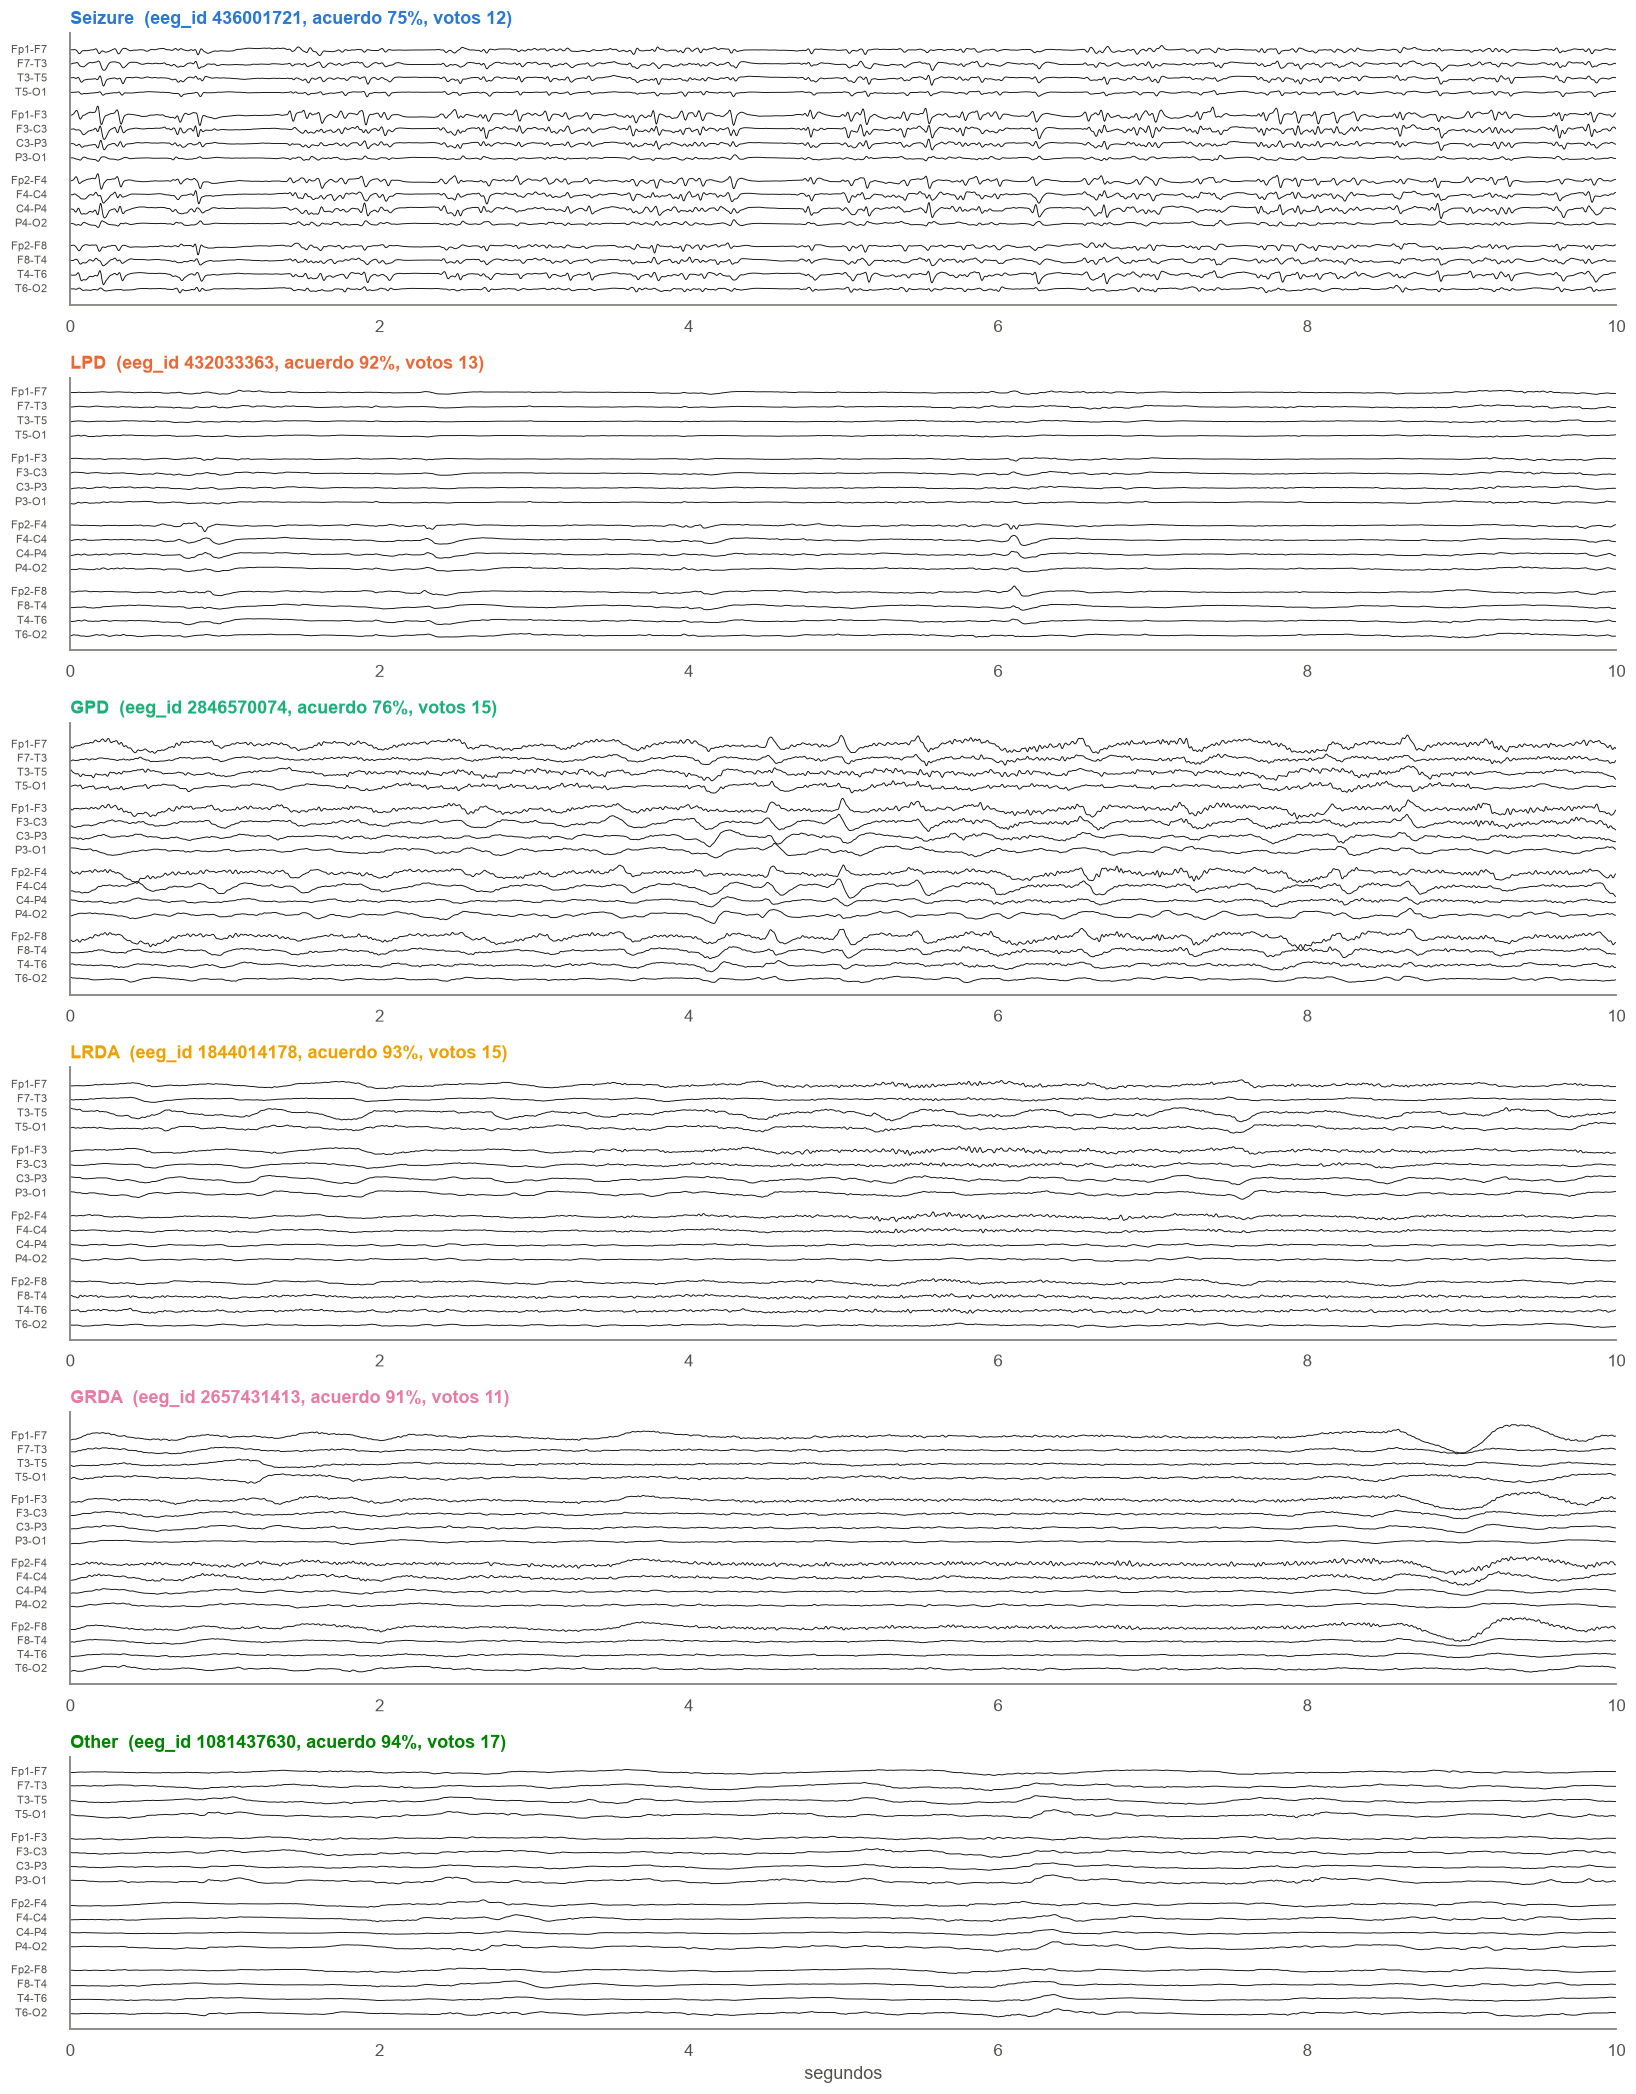

In [19]:
fig, axes = plt.subplots(len(CLASSES), 1, figsize=(15, 3.2 * len(CLASSES)))
for ax, c in zip(axes, CLASSES):
    cand = eeg_level[(eeg_level.expert_consensus == c) & (eeg_level.total_votes >= 10)]
    cand = cand[cand[TARGETS].max(axis=1) >= 0.75]
    r = cand.sample(1, random_state=3).iloc[0]
    w = clean_eeg(eeg_window(read_eeg(r.eeg_id), r.eeg_offset))
    w = w.iloc[20 * EEG_FS:30 * EEG_FS]
    mont = bipolar_montage(w)
    t = np.arange(len(w)) / EEG_FS
    k = 0
    for ch, sig in mont.items():
        for j, (a, b) in enumerate(CHAINS[ch]):
            ax.plot(t, sig[j] / 150 - k, lw=0.6, color="#0b0b0b")
            ax.text(-0.15, -k, f"{a}-{b}", ha="right", va="center", fontsize=7, color="#52514e")
            k += 1
        k += 0.6
    ax.set_title(f"{c}  (eeg_id {r.eeg_id}, acuerdo {r[TARGETS].max():.0%}, votos {r.total_votes:.0f})",
                 color=CLASS_COLORS[c], loc="left")
    ax.set_yticks([]); ax.set_xlim(0, 10); ax.grid(False)
axes[-1].set_xlabel("segundos")
fig.tight_layout(); fig.savefig(FIG / "eeg_ejemplos_clase.png"); plt.show()

Observaciones visuales coherentes con la definición clínica (ACNS):
- **Seizure**: actividad rítmica de alta frecuencia y amplitud que evoluciona en el tiempo.
- **LPD / GPD**: descargas (puntas/ondas agudas) que se repiten periódicamente — en un hemisferio
  (LPD) o en ambos de forma sincrónica (GPD).
- **LRDA / GRDA**: ondas lentas rítmicas (delta, ~1–3 Hz) lateralizadas o generalizadas.
- **Other**: fondo sin ninguno de los patrones anteriores.

La distinción lateralizada vs. generalizada depende de **comparar las cadenas izquierdas y
derechas**, por lo que la representación de entrada debe conservar la estructura espacial.

## 6. Espectrogramas de Kaggle

In [20]:
spec = read_kaggle_spectrogram(ex.spectrogram_id)
print("Forma:", spec.shape, "| columnas:", list(spec.columns[:3]), "...", list(spec.columns[-2:]))
regions = sorted({c.split("_")[0] for c in spec.columns if c != "time"})
freqs = sorted({float(c.split("_")[1]) for c in spec.columns if c != "time"})
print("Regiones:", regions, f"| {len(freqs)} frecuencias de {freqs[0]} a {freqs[-1]} Hz | paso temporal {spec.time.diff().median()} s")

Forma: (320, 401) | columnas: ['time', 'LL_0.59', 'LL_0.78'] ... ['RP_19.73', 'RP_19.92']
Regiones: ['LL', 'LP', 'RL', 'RP'] | 100 frecuencias de 0.59 a 19.92 Hz | paso temporal 2.0 s


In [21]:
sq = []
for r in sample.itertuples():
    s = read_kaggle_spectrogram(r.spectrogram_id)
    w = kaggle_spec_window(s, r.spec_offset).drop(columns="time")
    sq.append({"clase": r.expert_consensus, "filas": len(w), "nan_frac": w.isna().to_numpy().mean(),
               "log_pot_media": np.log(np.nanmean(w.to_numpy()) + 1e-6)})
sq = pd.DataFrame(sq)
print(f"Ventanas de 10 min con algún NaN: {(sq.nan_frac > 0).mean():.1%} (NaN medio {sq.nan_frac.mean():.2%})")
sq.describe().T.round(3)

Ventanas de 10 min con algún NaN: 6.3% (NaN medio 1.75%)


,count,mean,std,min,25%,50%,75%,max
filas,600.0,300.000,0.000,300.000,300.000,300.000,300.000,300.000
nan_frac,600.0,0.018,0.089,0.000,0.000,0.000,0.000,0.970
log_pot_media,600.0,3.071,2.937,-1.128,1.283,2.103,3.505,12.903


Los espectrogramas tienen 4 regiones (LL, LP, RP, RL) × 100 frecuencias (0.59–19.92 Hz) con
resolución de 2 s; la ventana de 10 minutos tiene ~300 columnas de tiempo. Su potencia tiene un
rango dinámico de varios órdenes de magnitud → se trabaja en **escala logarítmica**.

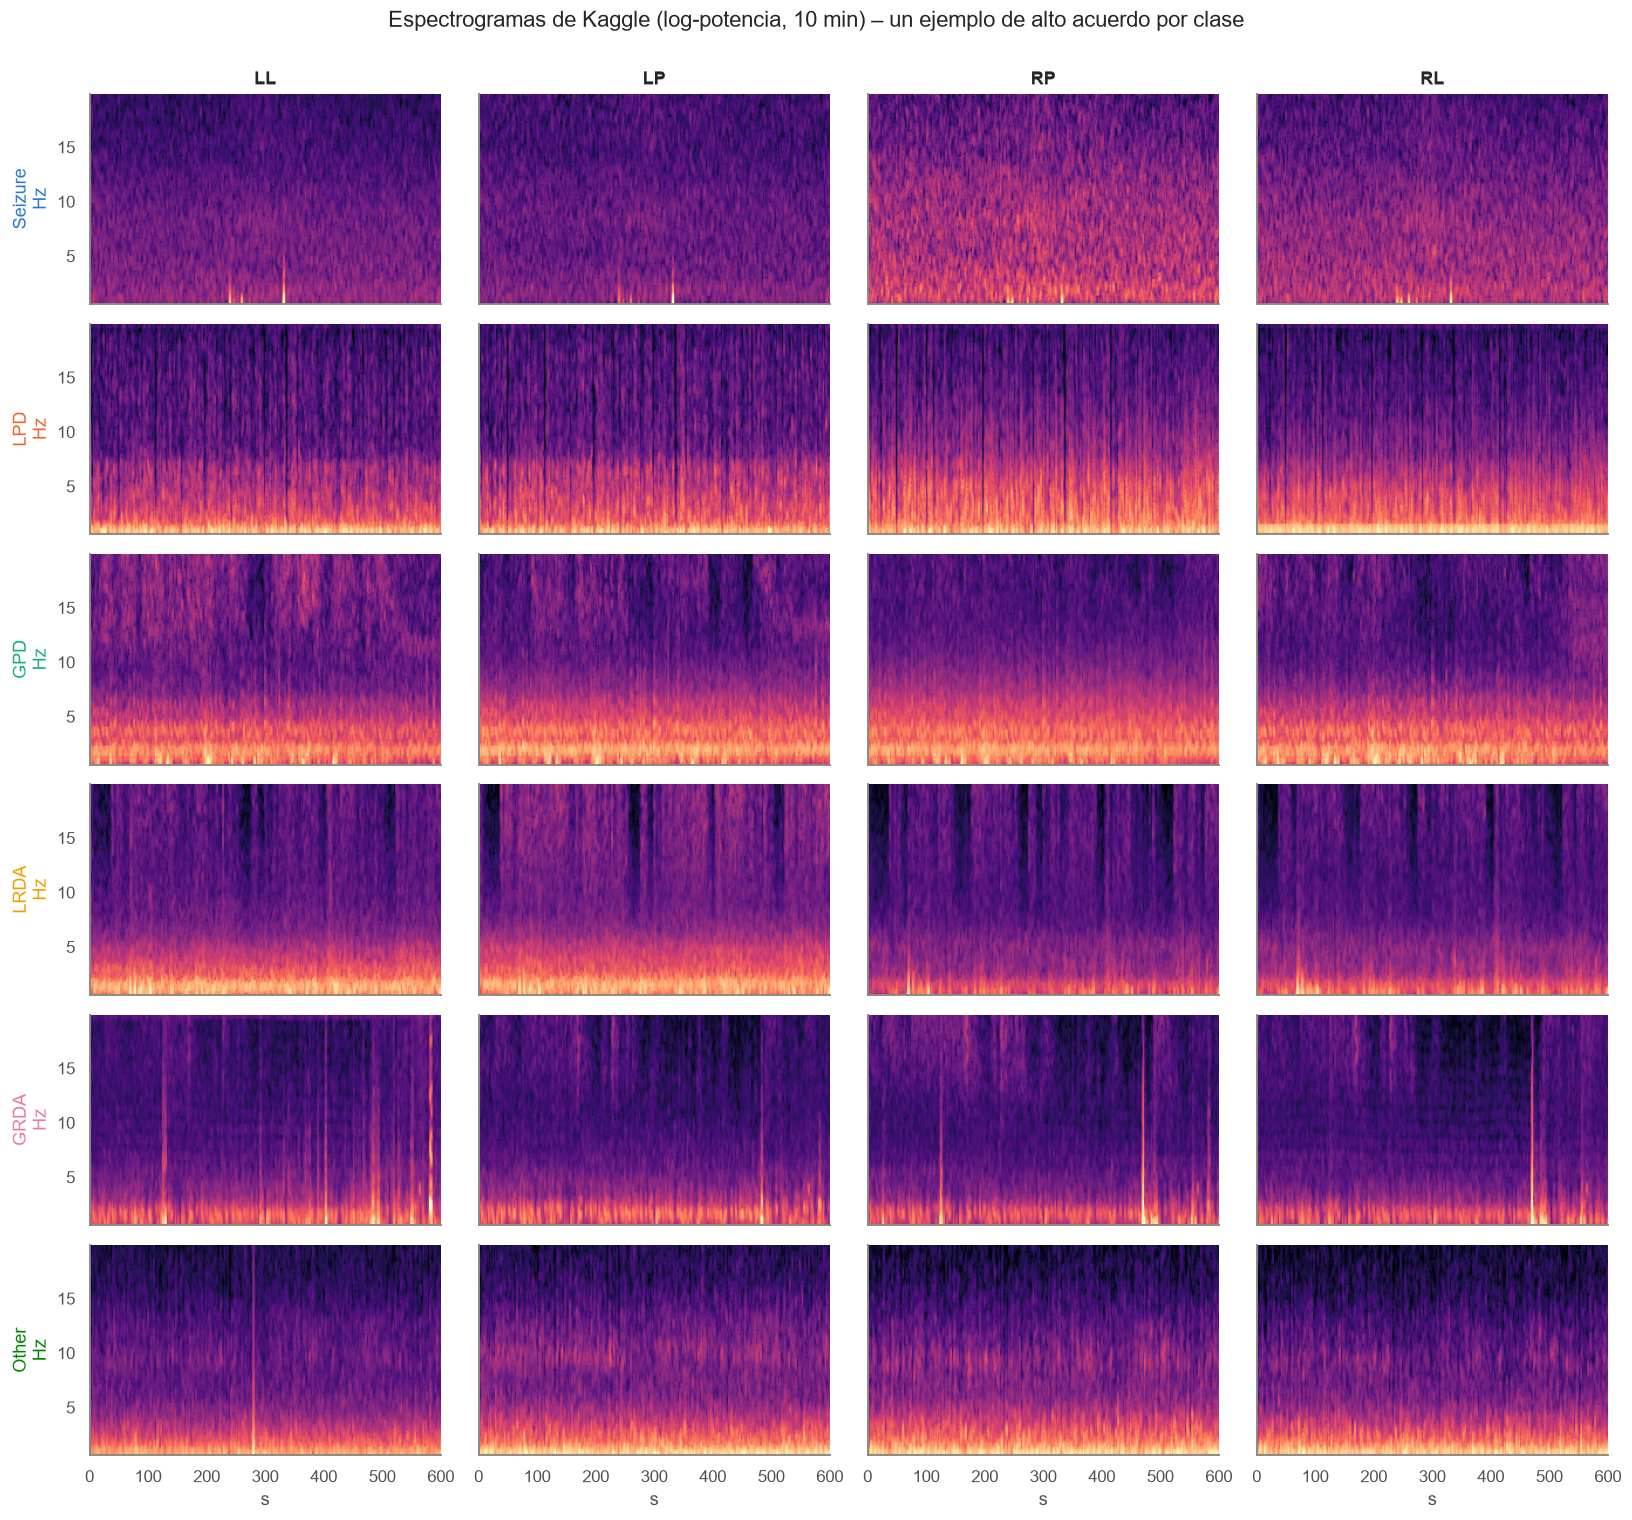

In [22]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(15, 2.3 * len(CLASSES)), sharex=True, sharey=True)
for i, c in enumerate(CLASSES):
    cand = eeg_level[(eeg_level.expert_consensus == c) & (eeg_level.total_votes >= 10)]
    r = cand[cand[TARGETS].max(axis=1) >= 0.75].sample(1, random_state=3).iloc[0]
    w = kaggle_spec_window(read_kaggle_spectrogram(r.spectrogram_id), r.spec_offset)
    for j, reg in enumerate(["LL", "LP", "RP", "RL"]):
        cols = [col for col in w.columns if col.startswith(reg + "_")]
        img = np.log(np.clip(w[cols].fillna(0).to_numpy().T, np.exp(-4), np.exp(8)))
        axes[i, j].imshow(img, origin="lower", aspect="auto", cmap="magma", extent=[0, 600, 0.59, 19.92])
        if i == 0: axes[i, j].set_title(reg)
        if j == 0: axes[i, j].set_ylabel(f"{c}\nHz", color=CLASS_COLORS[c])
        axes[i, j].grid(False)
for ax in axes[-1]: ax.set_xlabel("s")
fig.suptitle("Espectrogramas de Kaggle (log-potencia, 10 min) – un ejemplo de alto acuerdo por clase", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "espectrogramas_clase.png"); plt.show()

## 7. Potencia por bandas de frecuencia por clase
Se usan las features clásicas calculadas para todo el dataset en `src/build_cache.py`
(potencia relativa delta/theta/alpha/beta por región, varianza, *line-length*, asimetría izquierda-derecha).

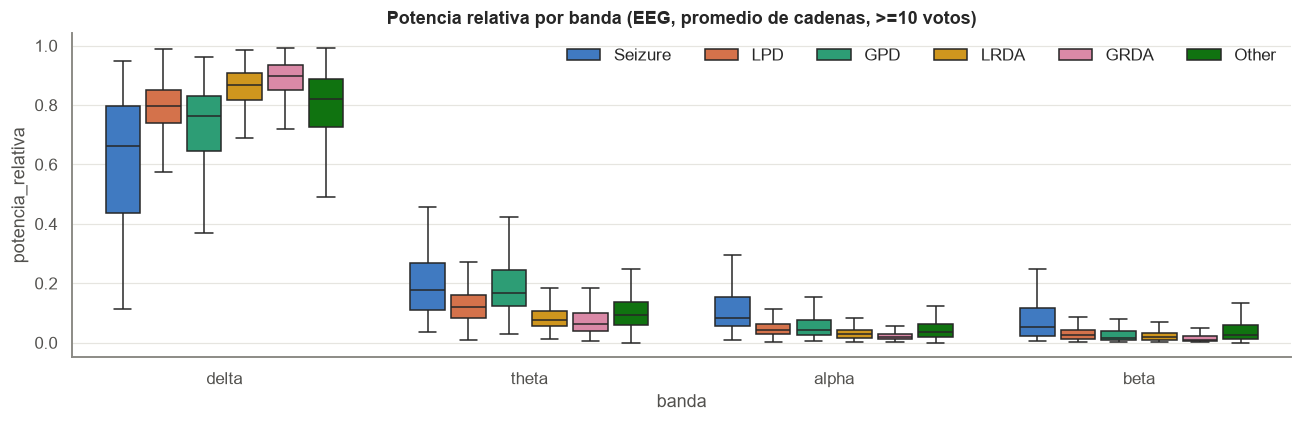

In [23]:
feats = pd.read_csv(CACHE_DIR / "band_features.csv")
meta_c = pd.read_csv(CACHE_DIR / "meta.csv")
df_f = pd.concat([meta_c[["expert_consensus", "total_votes"]], feats], axis=1)
df_f = df_f[meta_c.cache_ok & (df_f.total_votes >= 10)]
bands = ["delta", "theta", "alpha", "beta"]
long = []
for b in bands:
    v = df_f[[f"e_{ch}_{b}_rel" for ch in CHAINS]].mean(axis=1)
    long.append(pd.DataFrame({"banda": b, "potencia_relativa": v, "clase": df_f.expert_consensus}))
long = pd.concat(long)
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=long, x="banda", y="potencia_relativa", hue="clase", hue_order=CLASSES,
            palette=CLASS_COLORS, fliersize=0, ax=ax, gap=0.15)
ax.set_title("Potencia relativa por banda (EEG, promedio de cadenas, >=10 votos)")
ax.legend(ncol=6, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "bandas_clase.png"); plt.show()

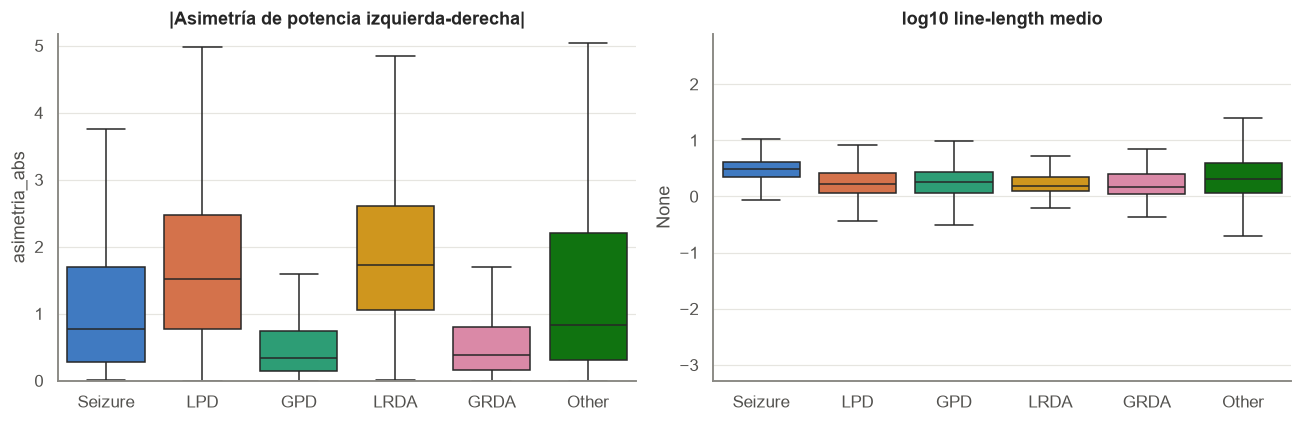

expert_consensus,Seizure,LPD,GPD,LRDA,GRDA,Other
asimetria_abs,0.766,1.514,0.345,1.721,0.387,0.838


In [24]:
df_f["asimetria_abs"] = df_f.e_lr_asym.abs()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df_f, x="expert_consensus", y="asimetria_abs", order=CLASSES, hue="expert_consensus",
            palette=CLASS_COLORS, fliersize=0, ax=axes[0], legend=False)
axes[0].set_title("|Asimetría de potencia izquierda-derecha|"); axes[0].set_xlabel("")
axes[0].set_ylim(0, df_f.asimetria_abs.quantile(0.95))
ll = df_f[[f"e_{ch}_linelen" for ch in CHAINS]].mean(axis=1)
sns.boxplot(x=df_f.expert_consensus, y=np.log10(ll.clip(lower=1e-3)), order=CLASSES, hue=df_f.expert_consensus,
            palette=CLASS_COLORS, fliersize=0, ax=axes[1], legend=False)
axes[1].set_title("log10 line-length medio"); axes[1].set_xlabel("")
fig.tight_layout(); fig.savefig(FIG / "asimetria_linelength.png"); plt.show()
df_f.groupby("expert_consensus")[["asimetria_abs"]].median().reindex(CLASSES).T.round(3)

Medianas en muestras de alta calidad:
- Las clases **lateralizadas (LPD 1.51, LRDA 1.72)** muestran una asimetría izquierda-derecha ~4 veces mayor
  que sus contrapartes generalizadas (GPD 0.35, GRDA 0.39).
- **GRDA (90 %) y LRDA (87 %)** concentran la mayor fracción de potencia en delta.
- **Seizure** tiene la menor fracción delta (66 %), la mayor en alpha/beta y la mayor *line-length*
  (≈3.1 vs. 1.5–2.0 del resto): actividad más rápida y de mayor amplitud. Las diferencias
existen pero las distribuciones se solapan mucho: las features agregadas no bastan, lo que motiva
usar representaciones tiempo-frecuencia completas con CNNs.

## 8. Conclusiones del EDA

| # | Hallazgo | Decisión para el modelado |
|---|----------|---------------------------|
| 1 | El objetivo es una distribución de votos; los expertos discrepan entre clases "vecinas" (LPD↔GPD, LRDA↔GRDA, Seizure↔LPD, todo↔Other). | Predecir distribución completa con **pérdida KL**; evaluar con KL (métrica oficial) además de accuracy/F1/AUC. |
| 2 | El número de votos varía (1–28); las muestras con <10 votos tienen otra distribución de clases y más ruido. | **Entrenamiento en dos etapas** (todo → afinado en ≥10 votos) y reporte de KL sobre alta calidad. |
| 3 | Las sub-ventanas de un mismo EEG son casi duplicadas. | **Una muestra por `eeg_id`** con la media de sus distribuciones de votos. |
| 4 | Pacientes casi monoclase y muy desbalanceados en cantidad de datos. | **Validación cruzada agrupada por paciente** (`StratifiedGroupKFold`, 5 folds). |
| 5 | El EEG tiene NaN, canales planos y artefactos de gran amplitud. | Imputación, **filtro 0.5–40 Hz**, recorte a ±1024 µV. |
| 6 | La información relevante está en la frecuencia (delta vs. rápida), la periodicidad y la lateralidad. | Representación **tiempo-frecuencia** (espectrogramas en log) por cadena bipolar, conservando izquierda/derecha → imágenes para **CNNs preentrenadas**. |
| 7 | Existen dos fuentes: espectrogramas de Kaggle (10 min de contexto) y EEG crudo (50 s, mayor detalle). | Combinar ambas en una sola imagen y medir el aporte de cada una (ablación). |